# Optimization 3 - Gradient Descent in action

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure Seaborn.
sns.set_style("whitegrid")
sns.set_palette("deep")

## 1 Partial Differentiation

### 1.1 Multivariate Calculus

#### One-Dimensional Function

- $y = f(x)$ is a one-dimensional function that maps a single independent input variable $x$ to a single output value $y$.
- One-Dimensional Function is also called as Univariate function.

#### Multi-Dimensional Function

- $y = f(x_1,\,x_2,\,\ldots,\,x_n)$ is a multi-dimensional function that maps a multiple independent input variables $x_1,\,x_2,\,\ldots,\,x_n$ to a single output value $y$.
- A Multi-Dimensional Function is also called as Multivariate or Multi-variable function.

> **Note**:
>
> Both One-dimensional and Multi-dimensional function produces only single output.

#### ML Context

In ML context, the **Loss Function** used in minimizing the error of a Machine Learning Algorithm is a **multivariate function**.

#### Derivatives of Multi-Dimensional Function

Derivatives of Multi-Dimensional Function is calculated using **Partial Differentiation**.

### 1.2 Partial Derivatives

#### Mathematical Intuition

- For a univariate function $f(x)$, there is a single derivative $f^\prime(x)$, which represents the slope of the tangent line at each point.
- Optimization algorithms use this derivative to determine the direction of movement toward a local Minima for a univariate function.
- For a multivariate function $f(x_1,\,x_2,\,\ldots,\,x_n)$, there is no single slope. Instead, the function has one partial derivative for each variable.
- For a multivariate function, the rate of change of the function is described by multiple partial derivatives.
- Together, the collection of these partial derivatives form the **Gradient**, which is a vector.
- Gradient vectors are used by Optimization algorithms to approach a local Minima for a multivariate function.

#### What is Partial Derivatives?

Given a multivariate function, process of calculating the derivative of that function w.r.t one variable at a time, considering all other variables as constant.

#### How to compute Partial Derivatives?

**Q**: How to Calculate Partial Derivatives of $f(x_1,\,x_2)$?

**Ans**:  
Partial derivatives of a multi-variable function $f(x_1,\,x_2)$ is represented as: 

$$
\large
\begin{aligned}
\frac{\partial}{\partial{x_1}} f(x_1,\,x_2) \\[10pt]
\frac{\partial}{\partial{x_2}} f(x_1,\,x_2)
\end{aligned}
$$

- Calculate derivative of $f(x_1,\,x_2)$ by changing $x_1$ and keeping $x_2$ as constant.
- Calculate derivative of $f(x_1,\,x_2)$ by changing $x_2$ and keeping $x_1$ as constant.

> **Note**:
>
> For a multivariate function slope is called as Gradient.

#### In ML Context

Given a Binary classification problem with the goal of minimizing the loss function $l(D,\,\vec{w},\,w_0)$ for feature vector $\vec{x}$ and weight vector $\vec{w}$:

$$
\large
l(D,\,\vec{w},\,w_0)\;=\;-\,\frac{1}{n}\,\sum_{i=1}^n\,\Biggl(\frac{{w^T}{x^{(i)}}\;+\;w_0}{\Vert{w}\Vert}\Biggr)\,\cdot\,y^{(i)}
$$

Partial derivative for $l(D,\,w_1,\,w_2,\,\ldots,\,w_n,\,w_0)$ is calculated as:

$$
\newcommand{\pdl}[1]{\frac{\partial}{\partial\,{#1}}&\,l(w_1,\,w_2,\,\ldots,\,w_n,\,w_0)}
\large
\begin{aligned}
\pdl{w_1} \\[10pt]
\pdl{w_2} \\[10pt]
\vdots    \\[5pt]
\pdl{w_n} \\[10pt]
\pdl{w_0} \\[10pt]
\end{aligned}
$$

> **Note**:
>
> The last derivative i.e., $\partial_{w_0}\,l(w_1,\,w_2,\,\ldots,\,w_n,\,w_0)$ will always be equal to 1.

#### Formula

Formula to calculate Partial derivative of any general function $f(x,\,y)$ with two variables $\{x,\,y\}$

$$
\large
\begin{aligned}
\frac{\partial}{\partial{x}} f(x,\,y) &= \lim_{\Delta{x}\,\to\,0} \frac{f(x + \Delta{x},\; y) - f(x,\,y)}{\Delta{x}} \\[20pt]
\frac{\partial}{\partial{y}} f(x,\,y) &= \lim_{\Delta{y}\,\to\,0} \frac{f(x,\; y + \Delta{y}) - f(x,\,y)}{\Delta{y}}
\end{aligned}
$$

#### Code

In [2]:
def get_partial_derivatives(func, x, y, delta=0.001):
    """
    Function to calculate the partial derivatives of
    given function `func` at any given point `x`, `y`.
    """
    df_dx = (func(x + delta, y) - func(x, y)) / delta
    df_dy = (func(x, y + delta) - func(x, y)) / delta

    return np.asarray([df_dx, df_dy])

In [3]:
v1 = get_partial_derivatives(func=lambda x, y: x**2 + y**2, x=3, y=4)
print("Gradient vector:", v1.round(6).tolist())

Gradient vector: [6.001, 8.001]


In [4]:
v2 = get_partial_derivatives(func=lambda x, y: x**2 + y**2, x=1.3, y=1.5)
print("Gradient vector:", v2.round(6).tolist())

Gradient vector: [2.601, 3.001]


### 1.3 Gradient

#### Definition

The Partial Derivative of a multivariate function represented in a vector form.

#### Properties

- In multivariate calculus the **slope of a tangent line** at any point, for example on a 3D shape, is called as **Gradient**.
- Since Gradient is a Vector it tells both direction and magnitude.

#### Mathematical Notation

Mathematical notation of a Gradient vector:

$$
\large
\nabla{f}
$$

#### How to compute Gradient Vector?

**Q**: How to calculate Partial Derivatives of $f(x_1,\,x_2)$ and determine its Gradient Vector?

**Ans**:  
Partial derivatives of a multi-variable function $f(x_1,\,x_2)$ is represented as: 

$$
\large
\begin{aligned}
\frac{\partial}{\partial{x_1}} f(x_1,\,x_2) \\[10pt]
\frac{\partial}{\partial{x_2}} f(x_1,\,x_2)
\end{aligned}
$$

- Calculate derivative of $f(x_1,\,x_2)$ by changing $x_1$ and keeping $x_2$ as constant.
- Calculate derivative of $f(x_1,\,x_2)$ by changing $x_2$ and keeping $x_1$ as constant.

At any given point, gradient is decided by partial derivative w.r.t $x_1$ and partial derivative w.r.t $x_2$.

$$
\newcommand{pd}[2]{\frac{\partial}{\partial{#1}} f\bigl(#2\bigr)}
\large
\nabla{f} = \Biggl(\pd{x_1}{x_1,\,x_2},\;\pd{x_2}{x_1,\,x_2}\Biggr)
$$

#### In ML Context

In ML context, gradient of a loss function for a Binary classification problem having feature vector $\vec{x}$ and weight vector $\vec{w}$:

$$
\large
l(D,\,\vec{w},\,w_0)\;=\;-\,\frac{1}{n}\,\sum_{i=1}^n\,\Biggl(\frac{{w^T}{x^{(i)}}\;+\;w_0}{\Vert{w}\Vert}\Biggr)\,\cdot\,y^{(i)}
$$

Equation to calculate Gradient Vector for the above scalar function $l(D,\,w_1,\,w_2,\,\ldots,\,w_n,\,w_0)$

$$
\large
\newcommand{\pdl}[1]{\displaystyle \frac{\partial}{\partial\,{#1}}\,l(\vec{w},\,w_0)}
\begin{aligned}
\nabla_{\overrightarrow{w},\,w_0}\,l(\vec{w},\,w_0) = 
\begin{bmatrix} 
\pdl{w_1} \\[8pt]
\pdl{w_2} \\[8pt]
\vdots    \\[5pt]
\pdl{w_d} \\[8pt]
\pdl{w_0}
\end{bmatrix}
\end{aligned}
$$

#### Example (In ML Context)

Given Binary classifier with two feature $\{x_1,\,x_2\}$ having weight vector $\vec{w}$, compute its partial derivative and Gradient vector.

$$
\large
\begin{aligned}
f(w_1,\,w_2,\,w_0) &= w_1 x_1 + w_2 x_2 + w_0 \\[5pt]
                 z &= w_1 x_1 + w_2 x_2 + w_0
\end{aligned}
$$

Partial derivatives of $z$:

$$
\large
\newcommand{\pdz}[1]{\frac{\partial}{\partial\,{#1}} z}
\begin{aligned}
\pdz{w_1} = x_1 + 0 + 0 = x_1 \\[8pt]
\pdz{w_2} = 0 + x_2 + 0 = x_2 \\[8pt]
\pdz{w_0} = 0\;+0\; + 1 = 1
\end{aligned}
$$

Gradient vector of $z$:

$$
\large
\nabla_{\vec{w},\,w_0} f(w_1,\,w_2,\,w_0) = \begin{bmatrix} x_1 \\[3pt] x_2 \\[3pt] 1 \end{bmatrix}
$$

> **Note**:
>
> Gradient Vector after taking Partial Derivative of $\;w^T \cdot x\;$ w.r.t to $\vec{w}$, will always be its Feature Vector $\vec{x}$.

#### Significance of Gradient Vector

The **Gradient** Vector of a scalar function is always pointing in the **direction of steepest ascent**.

### 1.4 Examples

#### Example 1

Calculate gradient of function:

$$
\large
f(x,\,y) = x^2 + 6xy + \log(y)
$$

##### Solution

Compute Partial derivative of $f(x, y)$ w.r.t $x$

$$
\large
\begin{aligned}
\frac{\partial}{\partial{x}} f(x,\,y) = 2x + 6y + 0 \\[10pt]
\boxed{
\rule{0pt}{20pt} \\
\quad \frac{\partial}{\partial{x}} f(x,\,y) = 2x + 6y \quad \\[15pt]
}
\end{aligned}
$$

Compute Partial derivative of $f(x, y)$ w.r.t $y$

$$
\large
\begin{aligned}
\frac{\partial}{\partial{y}} f(x,\,y) = 0 + 6x + \frac{1}{y} \\[10pt]
\boxed{
\rule{0pt}{20pt} \\
\quad \frac{\partial}{\partial{y}} f(x,\,y) = 6x + \frac{1}{y} \quad \\[15pt]
}
\end{aligned}
$$

Hence the equation of Gradient Vector:

$$
\large
\begin{aligned}
\nabla_{x,\,y}\,f(x,\,y) &= 
\begin{bmatrix} 
\displaystyle 2x + 6y \\[10pt] 
\displaystyle 6x + \frac{1}{y}
\end{bmatrix}
\end{aligned}
$$

#### Example 2

Calculate gradient of

$$
\large
f(x,\,y) = 3 \log (xy) + 4 y^2 x^3
$$

##### Solution

Compute Partial derivative of $f(x, y)$ w.r.t $x$

$$
\large
\begin{aligned}
\frac{\partial}{\partial{x}} f(x,\,y) = 3 \frac{1}{x\cancel{y}}\cancel{y} + (4y^2 \cdot 3x^2) \\[10pt]
\boxed{
\rule{0pt}{20pt} \\
\quad \frac{\partial}{\partial{x}} f(x,\,y) = \frac{3}{x} + 12 y^2 x^2 \quad \\[15pt]
}
\end{aligned}
$$

Compute Partial derivative of $f(x, y)$ w.r.t $y$

$$
\large
\begin{aligned}
\frac{\partial}{\partial{y}} f(x,\,y) = 3 \frac{1}{\cancel{x}{y}}\cancel{x} + (4 \cdot 2y \cdot x^3) \\[10pt]
\boxed{
\rule{0pt}{20pt} \\
\quad \frac{\partial}{\partial{y}} f(x,\,y) = \frac{3}{y} + 8y x^3 \quad \\[15pt]
}
\end{aligned}
$$

Hence the equation of Gradient Vector:

$$
\large
\begin{aligned}
\nabla_{x,\,y}\,f(x,\,y) = 
\begin{bmatrix} 
\displaystyle \frac{3}{x} + 12 y^2 x^2 \\[10pt] 
\displaystyle \frac{3}{y} + 8y x^3
\end{bmatrix}
\end{aligned}
$$

## 2 Gradient Descent Algorithm

### 2.1 Gradient Update Rule

#### Intuition for Gradient Descent

- Goal of using Gradient Descent Algorithm is to **reach minimum**.
- Gradient Vector always points in the direction of the steepest local ascent of the function.
- Therefore **negative of Gradient Vector** will point in **steepest local descent** (towards minima).
- Hence Gradient is always updated by subtracting it from the original value.

#### Gradient Update Rule (GUR)

Equation for a Gradient update rule:

$$
\large
x^n = x^o\;-\;\frac{\partial}{\partial{x}}f(x^o)
$$

Where,

- $x$ - Some random vector (not features)
- $x^n$ - New $x$ values after update
- $x^o$ - Old $x$ values before update

#### Steps in GUR

- **STEP #1**: Initialize random value of $x$.
- **STEP #2**: Compute the derivatives (Gradient Vector).
- **STEP #3**: Subtract the derivatives from $x$ to descent towards Minima.
- **STEP #4**: Repeat STEP #1 to STEP #4 until convergence at local minima.

#### Issues with GUR

- Updating the value of $x$ directly in an uncontrolled manner using only $f^\prime(x)$ can result in toggling.
- Toggling is where $x$ keeps updating between same two values.
- Hence we need a mechanism to control the descent.

#### Learning Rate

- Learning rate $\eta$ is a Hyper-parameter that controls the step size of the descent.
- Too large value of $\eta$ can offshoot the descent.
- Too small values slows down the learning.
- Hence an optimal value must be decided by the end user.

#### GUR With Learning Rate

Equation for a Gradient update rule:

$$
\large
x^n = x^o\;-\;\eta\,\frac{\partial}{\partial{x}}f(x^o)
$$

Where,

- $x$ - Some random vector (not features)
- $x^n$ - New $x$ values after update
- $x^o$ - Old $x$ values before update
- $\eta$ - Learning Rate

### 2.2 Implementation of GDA

#### Gradient Update Rule (In ML Context)

$$
\large
\begin{aligned}
{\vec{w}}^{\text{new}} = {\vec{w}}^{\text{old}}\;-\;\eta\,\frac{\partial}{\partial\vec{w}}f({\vec{w}}^{\text{old}}) \\[8pt]
w_0^{\text{new}} = w_0^{\text{old}}\;-\;\eta\,\frac{\partial}{\partial{w_0}}f(w_0^{\text{old}})
\end{aligned}
$$

Where,

- ${\vec{w}}^{\text{new}}$ - New Gradient vector $w$ after update
- ${\vec{w}}^{\text{old}}$ - Old Gradient vector $w$ before update
- $w_0^{\text{new}}$ - New Bias $w_0$ value after update
- $w_0^{\text{old}}$ - Old Bias $w_0$ value before update
- $\eta$ - Learning Rate

#### Sudocode

- **STEP 1**: Initialize Weight vector $w$ with some random values.
- **STEP 2**: Initialize Learning Rate $\eta$ with some small random value.
- **STEP 3**: Repeat below **Gradient Update Rule** until convergence.
   - **STEP 3.1**: Compute derivatives of Loss function $l(D,\,w,\,w_0)$ (a.k.a gradient vector).
   - **STEP 3.2**: Multiply the new Gradient Vector from STEP 3.1 with Learning Rate $\eta$.
   - **STEP 3.3**: Subtract old weights $w^{\text{old}}$ with the new Gradient Vector from STEP 3.2.
   - **STEP 3.4**: Store the updated weights from STEP 3.3 in $w^{\text{new}}$ (to be reused as $w^{\text{old}}$ in next iteration).

#### Derivative Function

In [5]:
def derivative(func, x, delta=0.0001):
    """
    Function to calculate derivative of the
    given function `func` w.r.t `x` vector.
    """
    # General form of derivative.
    df_dx = (func(x + delta) - func(x)) / delta

    return df_dx

#### Gradient Descent Algorithm

Implementation of Gradient descent Algorithm in Python.

In [6]:
def gradient_descent(func, w=0, lr=0.01):
    """
    Function to apply Gradient Descent Algorithm on the given function `func`
    using some randomly initialed weight vector `w` and learning rate `lr`.
    """
    convergence = False
    tolerance = 1e-6  # 10^-6 or 0.000001

    # Initialize weight vector and learning rate.
    w_log = [w]
    eta = lr

    max_iter = 10_000
    itr = 0
    while (not convergence) and (itr < max_iter):
        # Compute derivative of loss function.
        grad_vec = derivative(func, w_log[-1])

        # Apply Gradient Update Rule.
        w_new = w_log[-1] - (eta * grad_vec)

        # Check for convergence.
        if abs(grad_vec) < tolerance:
            convergence = True

        w_log.append(w_new)
        itr += 1

    if itr == max_iter:
        raise ValueError("Max iteration reached. Try increasing learning rate.")

    return w_log, itr

### 2.3 Examples

#### Example #1

Find minima for the given function: $f(x) = x^2 + 4x - 10$

In [7]:
def f(x):
    """
    Function representing mathematical function:
    f(x) = x^2 + 4x - 10
    """
    return x**2 + (4 * x) - 10


# `f_vec` is vectorized version of function `f` to support numpy operations.
f_vec = np.vectorize(f)

In [8]:
x = np.arange(-80, 80, 0.01)
y = f_vec(x)  # Same as: y = f(x)

Plot function $f(x) = x^2 + 4x - 10$

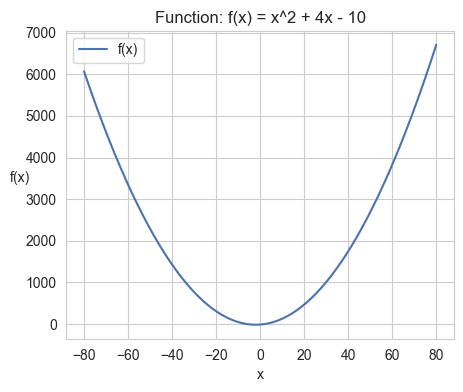

In [9]:
plt.figure(figsize=(5, 4))

sns.lineplot(x=x, y=y, label="f(x)")
plt.title("Function: f(x) = x^2 + 4x - 10")
plt.xlabel("x")
plt.ylabel("f(x)", rotation=0)

plt.show()

GD in Action

In [10]:
# Historical values of Gradient Vector `w` and iteration count.
w_hist, itr_count = gradient_descent(func=f, w=-50, lr=0.1)
print(f"Reached convergence in {itr_count} iterations.")
w_hist[-3:]

Reached convergence in 84 iterations.


[-2.000050542777032, -2.0000504342220893, -2.0000503473760034]

Plot Gradient Descent

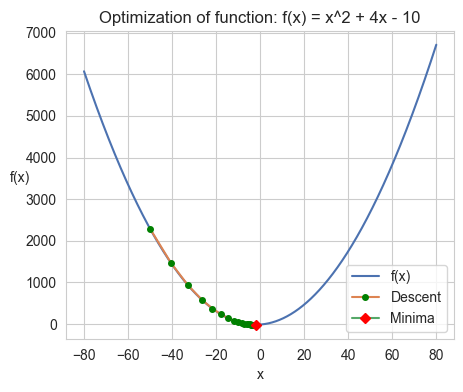

In [11]:
plt.figure(figsize=(5, 4))

# Plot function.
sns.lineplot(x=x, y=y, label="f(x)")
plt.title("Optimization of function: f(x) = x^2 + 4x - 10")
plt.xlabel("x")
plt.ylabel("f(x)", rotation=0)

# Plot descent towards minima.
plot_params = {"marker": "o", "markersize": 4, "markerfacecolor": "g", "markeredgecolor": "g"}
plt.plot(w_hist[:-1], f_vec(w_hist)[:-1], label="Descent", **plot_params)

# Highlight minima by plotting it separately.
plot_params = {"marker": "D", "markersize": 5, "markerfacecolor": "r", "markeredgecolor": "r"}
plt.plot(w_hist[-1], f_vec(w_hist)[-1], label="Minima", **plot_params)

plt.legend()
plt.show()

##### Observations

Optimization of Example 1 was successful in reaching Global Minima.

#### Example #2

Find minima for the given function: $f(x) = x^4 + 14x^2 + 24x + 10\sin(5x)$

In [12]:
def f(x):
    """
    Function representing mathematical function:
    f(x) = x^4 + 14x^2 + 24x + 10sin(5x)
    """
    return x**4 - (14 * x**2) + (24 * x) + (10 * np.sin(5 * x).item())


# `f_vec` is vectorized version of function `f` to support numpy operations.
f_vec = np.vectorize(f)

In [13]:
x = np.arange(-5, 4, 0.01)
y = f_vec(x)  # Same as: y = f(x)

Plot function $f(x) = x^4 + 14x^2 + 24x + 10\sin(5x)$

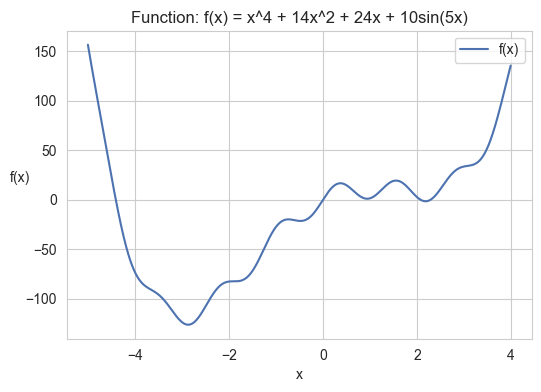

In [14]:
plt.figure(figsize=(6, 4))

sns.lineplot(x=x, y=y, label="f(x)")
plt.title("Function: f(x) = x^4 + 14x^2 + 24x + 10sin(5x)")
plt.xlabel("x")
plt.ylabel("f(x)", rotation=0)

plt.show()

GD in Action

In [15]:
try:
    gradient_descent(func=f, lr=0.01)
except ValueError as e:
    print("ERROR:", e)

ERROR: Max iteration reached. Try increasing learning rate.


In [16]:
# Historical values of Gradient Vector `w` and iteration count.
w_hist, itr_count = gradient_descent(func=f, lr=0.031)
print(f"Reached convergence in {itr_count} iterations.")
w_hist[-2:]

Reached convergence in 41 iterations.


[-1.8842975471766632, -1.8842975303525744]

Plot Gradient Descent

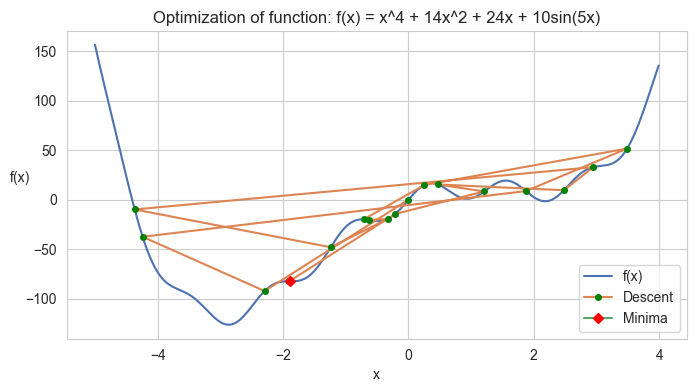

In [17]:
plt.figure(figsize=(8, 4))

# Plot function.
sns.lineplot(x=x, y=y, label="f(x)")
plt.title("Optimization of function: f(x) = x^4 + 14x^2 + 24x + 10sin(5x)")
plt.xlabel("x")
plt.ylabel("f(x)", rotation=0)

# Plot descent towards minima.
plot_params = {"marker": "o", "markersize": 4, "markerfacecolor": "g", "markeredgecolor": "g"}
plt.plot(w_hist[:-1], f_vec(w_hist)[:-1], label="Descent", **plot_params)

# Highlight minima by plotting it separately.
plot_params = {"marker": "D", "markersize": 5, "markerfacecolor": "r", "markeredgecolor": "r"}
plt.plot(w_hist[-1], f_vec(w_hist)[-1], label="Minima", **plot_params)

plt.legend()
plt.show()

##### Observations

Optimization of Example 2 could not reach local/global minima instead reached a Saddle Point.